In [1]:
print("kagle")

kagle


In [7]:
import kagglehub
path = kagglehub.dataset_download("yadavhim/placement-csv")
print("Path to dataset files:", path)

100%|██████████| 3.65k/3.65k [00:00<00:00, 2.32MB/s]

Extracting files...
Path to dataset files: C:\Users\rwam\.cache\kagglehub\datasets\yadavhim\placement-csv\versions\1


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
df= pd.read_csv("placement.csv")

In [10]:
df.sample(5)

,cgpa,placement_exam_marks,placed
626,7.63,19.0,1
498,6.89,14.0,0
806,6.39,15.0,0
244,7.68,44.0,0
113,7.24,10.0,0


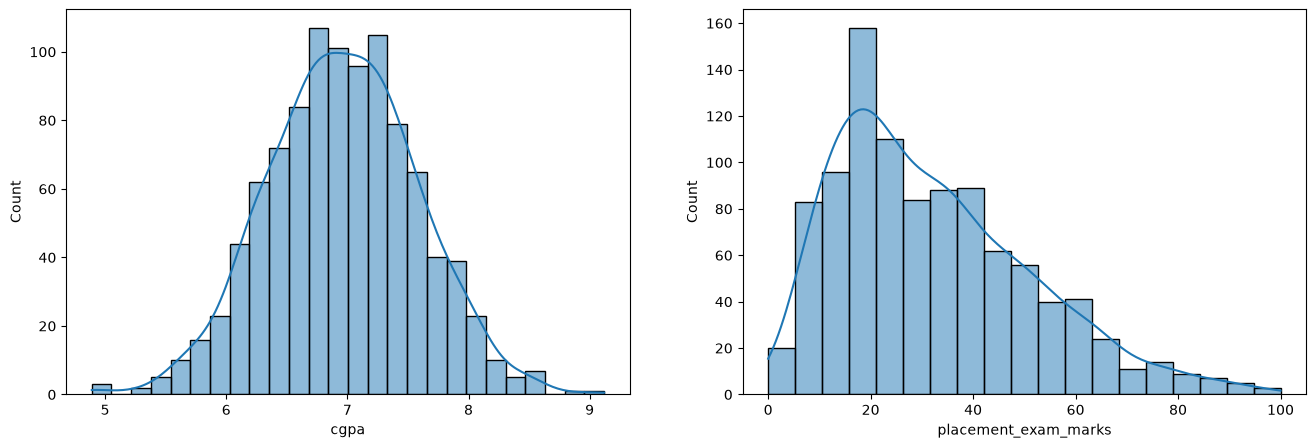

In [35]:
plt.figure(figsize=(16,5))

plt.subplot(1,2,1)
sns.histplot(df["cgpa"], kde=True)

plt.subplot(1,2,2)
sns.histplot(df["placement_exam_marks"],kde=True)

plt.show()

In [48]:
df["cgpa"].describe()


count    1000.000000
mean        6.961240
std         0.615898
min         4.890000
25%         6.550000
50%         6.960000
75%         7.370000
max         9.120000
Name: cgpa, dtype: float64

In [52]:
highest=df["cgpa"].mean()+3*df["cgpa"].std()
lowest=df["cgpa"].mean()-3*df["cgpa"].std()

In [53]:
highest,lowest

(np.float64(8.808933625397168), np.float64(5.113546374602832))

In [55]:
df[(df["cgpa"]>8.80) | (df["cgpa"]<5.11)]

,cgpa,placement_exam_marks,placed
485,4.92,44.0,1
995,8.87,44.0,1
996,9.12,65.0,1
997,4.89,34.0,0
999,4.90,10.0,1


In [58]:
newdf= df[(df["cgpa"]<8.80) & (df["cgpa"]>5.11)].dropna()
newdf

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0
...,...,...,...
991,7.04,57.0,0
992,6.26,12.0,0
993,6.73,21.0,1
994,6.48,63.0,0


In [59]:
df["cgpa_zscore"]= (df["cgpa"]-df["cgpa"].mean())/df["cgpa"].std()

In [60]:
df.head()

,cgpa,placement_exam_marks,placed,cgpa_zscore
0,7.19,26.0,1,0.371425
1,7.46,38.0,1,0.809810
2,7.54,40.0,1,0.939701
3,6.42,8.0,1,-0.878782
4,7.23,17.0,0,0.436371


In [63]:
df[ (df["cgpa_zscore"]> 3) | (df["cgpa_zscore"]<-3)]

,cgpa,placement_exam_marks,placed,cgpa_zscore
485,4.92,44.0,1,-3.314251
995,8.87,44.0,1,3.099150
996,9.12,65.0,1,3.505062
997,4.89,34.0,0,-3.362960
999,4.90,10.0,1,-3.346724


In [66]:
newdf=df[ (df["cgpa_zscore"]< 3) & (df["cgpa_zscore"]>-3)]

In [67]:
newdf

,cgpa,placement_exam_marks,placed,cgpa_zscore
0,7.19,26.0,1,0.371425
1,7.46,38.0,1,0.809810
2,7.54,40.0,1,0.939701
3,6.42,8.0,1,-0.878782
4,7.23,17.0,0,0.436371
...,...,...,...,...
991,7.04,57.0,0,0.127878
992,6.26,12.0,0,-1.138565
993,6.73,21.0,1,-0.375452
994,6.48,63.0,0,-0.781363


In [68]:
df["cgpa"]= np.where(

df["cgpa"]>highest,
highest,
np.where(
    df["cgpa"]<lowest,
    lowest,
    df["cgpa"]
)



)

In [70]:
df.describe()

,cgpa,placement_exam_marks,placed,cgpa_zscore
count,1000.000000,1000.000000,1000.000000,1.000000e+03
mean,6.961499,32.225000,0.489000,-1.465494e-16
std,0.612688,19.130822,0.500129,1.000000e+00
min,5.113546,0.000000,0.000000,-3.362960e+00
25%,6.550000,17.000000,0.000000,-6.677081e-01
50%,6.960000,28.000000,0.000000,-2.013321e-03
75%,7.370000,44.000000,1.000000,6.636815e-01
max,8.808934,100.000000,1.000000,3.505062e+00


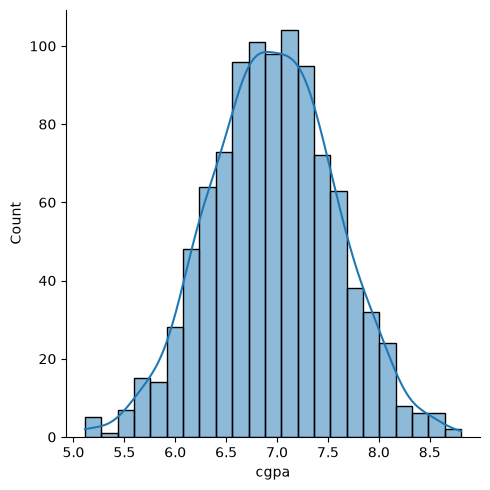

In [71]:

sns.displot(df["cgpa"], kde=True)